# Week 10B: Databases, Census APIs, and demographic maps

Use SQL to manage records, query Census demographic data, and build a racial dot map for Philadelphia.

**Lecture guide:** Database basics → Census API fundamentals → Query demographic data → Join geometries → Build a dot map

## Today’s agenda

- Practice relational database operations with SQLite.
- Query Census metadata and ACS estimates with `requests`.
- Download Census boundary files and join them to demographic records.
- Generate a reproducible racial dot map for Philadelphia.

## Part 1: Database basics with SQLite

Relational databases organize data into tables. SQL lets us create tables and insert, query, update, or delete records. Common database systems include SQLite, PostgreSQL, MySQL, DuckDB, and Microsoft SQL Server.

For spatial data, PostgreSQL can use the PostGIS extension to store and query geographic objects. Databases help manage large datasets and repeated queries. Recently, the DuckDB has become an emerging DB for spatial data. 

We’ll use a small SQLite database of student records to practice the basic SQL operations.

### Step 1: Connect to a SQLite database

Use an in-memory database for this exercise. Rerunning the setup starts fresh and does not modify an existing `students.db` file. A file-backed connection such as `sqlite3.connect("students.db")` persists records between sessions.

In [74]:
import sqlite3
conn = sqlite3.connect(":memory:")
cur = conn.cursor()

### Step 2: Create a table

In [75]:
cur.execute("""
CREATE TABLE IF NOT EXISTS students (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT,
    major TEXT,
    gpa REAL
)
""")
conn.commit()

### Step 3: Insert records

In [76]:
# Fixed IDs make this cell safe to rerun without duplicate students.
cur.executemany(
    "INSERT OR REPLACE INTO students (id, name, major, gpa) VALUES (?, ?, ?, ?)",
    [(1, "Alice", "Urban Studies", 3.8), (2, "Bob", "Environmental Science", 3.5)],
)
conn.commit()

### Step 4: Query records

In [77]:
cur.execute("SELECT * FROM students")
rows = cur.fetchall()

for row in rows:
    print(row)

(1, 'Alice', 'Urban Studies', 3.8)
(2, 'Bob', 'Environmental Science', 3.5)


### Step 5: Update and delete records

In [78]:
cur.execute("UPDATE students SET gpa = 3.9 WHERE name = 'Alice'")
cur.execute("DELETE FROM students WHERE name = 'Bob'")
conn.commit()
print(cur.execute("SELECT * FROM students").fetchall())
# Close when finished with the exercise.
conn.close()

[(1, 'Alice', 'Urban Studies', 3.9)]


### Set up the geospatial Python tools

Use the course geospatial environment with `requests`, pandas, NumPy, GeoPandas (1.0 or newer), Shapely (2.0 or newer), and Matplotlib. The optional interactive preview uses folium and mapclassify.

If needed, install dependencies **before** the lecture in the notebook's environment, then restart its kernel:

```python
%pip install "geopandas>=1.0" "shapely>=2.0" pandas numpy matplotlib requests folium mapclassify
```

Keep package installation separate from the data-analysis cells so the kernel uses a consistent environment throughout the lesson.

In [79]:
import os
from getpass import getpass
from io import BytesIO, StringIO

import geopandas as gpd
import numpy as np
import pandas as pd
import requests
from matplotlib import pyplot as plt
from shapely import contains_xy
from shapely.geometry import Point

In [80]:
pd.options.display.max_columns = 999
pd.options.display.max_colwidth = None

## Part 2: Census API fundamentals

### US Census data is foundational

- Rich data sets with annual releases
- Decennial results plus American Community Survey (ACS) results
- Wide range of topics covered: sex, income, poverty, education, housing

### Browse data at data.census.gov

<center>
    <a href=https://data.census.gov/><img src="imgs/census-2.png" width=700></img></a>
</center>

### Example: Poverty data
<center>
    <a href="https://data.census.gov/table/ACSST1Y2021.S1701?q=poverty+status&g=010XX00US$0400000&tid=ACSST1Y2021.S1701"><img src="imgs/poverty-1.png" width=900></img></a>
</center>

#### Understand the API request

[https://api.census.gov/data/2021/acs/acs1?get=NAME,B17001_002E&for=state:*](https://api.census.gov/data/2021/acs/acs1?get=NAME,B17001_002E&for=state:*)

- **Base endpoint:** https://api.census.gov/data/2021/acs/acs1
- **Request parameters:** "get", "for"

**Current requirement:** Census data queries need an activated API key. The example URL above illustrates the parameters; add your key through Python below rather than publishing a key in a notebook or link.

![](imgs/poverty-2.png)

### Find variable names

The census provides web-based documentation:

- Overview of all data tables: [https://api.census.gov/data.html](https://api.census.gov/data.html)
- All data tables for 2021: [https://api.census.gov/data/2021.html](https://api.census.gov/data/2021.html)
- All variables for 2021 ACS 5-year data set: [https://api.census.gov/data/2021/acs/acs5/variables.html](https://api.census.gov/data/2021/acs/acs5/variables.html)

#### Census API reference guide

[https://www.census.gov/data/developers/guidance/api-user-guide.html](https://www.census.gov/data/developers/guidance/api-user-guide.html)

### Access Census data with Python

Use `requests.get()` to send queries directly to the Census API, then convert the JSON responses into pandas DataFrames. This keeps the endpoint, query parameters, and response checks visible.

Census requires a free, activated API key for data queries: [official guidance](https://www.census.gov/library/video/2026/adrm/requesting-a-census-data-api-key.html). We will set up the key before requesting demographic estimates.

A missing key can return an HTML **Missing Key** page with HTTP status 200. Check the response before calling `.json()`; otherwise parsing the HTML as JSON raises `JSONDecodeError`. The `census_json()` helper below performs these checks.

## Part 3: Query Census data and join geometries

### Goal: A racial dot map for Philadelphia

![](imgs/racial-dot-map.png)

Source: [Washington Post](https://www.washingtonpost.com/graphics/2018/national/segregation-us-cities/)

Let's make this for Philadelphia in Python!

### Set up explicit Census API requests

In [81]:
ACS_YEAR = 2021
acs_endpoint = f"https://api.census.gov/data/{ACS_YEAR}/acs/acs5"

def census_json(url, params=None):
    """Request Census JSON, with useful errors and no API key in messages."""
    params = dict(params or {})
    try:
        response = requests.get(url, params=params, timeout=60)
    except requests.RequestException:
        raise RuntimeError("Census request failed. Check your connection and retry later.") from None
    text = response.text.strip()
    if "missing key" in text.lower() or "invalid key" in text.lower():
        raise RuntimeError("Census requires a valid, activated API key. Rerun the key setup cell.")
    if not response.ok:
        # Redact the key before showing the API's explanation.
        detail = text[:500].replace(params.get("key") or "<no-key>", "[redacted]")
        raise RuntimeError(f"Census HTTP {response.status_code}: {detail}")
    if text.startswith("<"):
        raise RuntimeError("Census returned HTML, not JSON. Check key activation or service availability.")
    try:
        payload = response.json()
    except ValueError:
        raise RuntimeError("Census returned a non-JSON response. Retry later and check the endpoint.") from None
    if isinstance(payload, dict) and "error" in payload:
        detail = str(payload["error"]).replace(params.get("key") or "<no-key>", "[redacted]")
        raise RuntimeError(f"Census API error: {detail}")
    return payload

In [82]:
# Public metadata requests do not need your personal data-query key.
metadata = census_json(acs_endpoint + ".json")

#### Explore Census metadata directly

- Dataset descriptions: the endpoint's `.json` metadata catalog.
- Variables: `variables.json` beneath the endpoint.
- Geographic hierarchy: `geography.json` beneath the endpoint.
- County FIPS codes: the Census Bureau's public county reference, shown below.

Use `census_json()` to load the JSON metadata into ordinary Python dictionaries, then organize the records with pandas.

**Note: we can change pandas display options to see all rows/columns and large cells**

In [83]:
# UNCOMMENT TO SEE ALL ROWS/COLUMNS IN DATAFRAMES
# pd.options.display.max_rows = 9999 
# pd.options.display.max_colwidth = 200

### Step 1: Choose the Census dataset

- Today, we'll use the 5-year American Community Survey (2021 example dataset)
- Other common datasets: 
    - 1-year ACS datasets as well (2022 example dataset)
    - 10-year decennial survey (2020 example dataset)

In [84]:
available = pd.DataFrame(metadata["dataset"])
available["dataset_id"] = available["identifier"].str.rsplit("/", n=1).str[-1]
available = available.set_index("dataset_id")
available[["title", "description"]].head()

,title,description
dataset_id,,
ACSDT5Y2021,American Community Survey: 5-Year Estimates: Detailed Tables 5-Year,"The American Community Survey (ACS) is an ongoing survey that provides data every year -- giving communities the current information they need to plan investments and services. The ACS covers a broad range of topics about social, economic, demographic, and housing characteristics of the U.S. population. Summary files include the following geographies: nation, all states (including DC and Puerto Rico), all metropolitan areas, all congressional districts, all counties, all places, and all tracts and block groups. Summary files contain the most detailed cross-tabulations, many of which are published down to block groups. The data are population and housing counts. There are over 64,000 variables in this dataset."
ACSCP5Y2021,American Community Survey: 5-Year Estimates: Comparison Profiles 5-Year,"The American Community Survey (ACS) is an ongoing survey that provides data every year -- giving communities the current information they need to plan investments and services. The ACS covers a broad range of topics about social, economic, demographic, and housing characteristics of the U.S. population. The Comparison Profiles include the following geographies: nation, all states (including DC and Puerto Rico), all metropolitan areas, all congressional districts, all counties, all places and all tracts. Comparison Profiles contain broad social, economic, housing, and demographic information. The data are presented as both counts and percentages. There are over 2,400 variables in this dataset."
ACSDP5Y2021,American Community Survey: 5-Year Estimates: Data Profiles 5-Year,"The American Community Survey (ACS) is an ongoing survey that provides data every year -- giving communities the current information they need to plan investments and services. The ACS covers a broad range of topics about social, economic, housing, and demographic characteristics of the U.S. population. The ACS 5-year data profiles include the following geographies: nation, all states (including DC and Puerto Rico), all metropolitan areas, all congressional districts, all counties, all places and all tracts. The Data profiles contain broad social, economic, housing, and demographic information. The data are presented as both counts and percentages. There are over 2,400 variables in this dataset."
ACSST5Y2021,American Community Survey: 5-Year Estimates: Subject Tables 5-Year,"The American Community Survey (ACS) is an ongoing survey that provides data every year -- giving communities the current information they need to plan investments and services. The ACS covers a broad range of topics about social, economic, demographic, and housing characteristics of the U.S. population. The subject tables include the following geographies: nation, all states (including DC and Puerto Rico), all metropolitan areas, all congressional districts, all counties, all places and all tracts. Subject tables provide an overview of the estimates available in a particular topic. The data are presented as both counts and percentages. There are over 66,000 variables in this dataset."
ACSPUMS5Y2021,2021 American Community Survey: 5-Year Estimates - Public Use Microdata Sample,"The American Community Survey (ACS) Public Use Microdata Sample (PUMS) contains a sample of responses to the ACS. The ACS PUMS dataset includes variables for nearly every question on the survey, as well as many new variables that were derived after the fact from multiple survey responses (such as poverty status).Each record in the file represents a single person, or, in the household-level dataset, a single housing unit. In the person-level file, individuals are organized into households, making possible the study of people within the contexts of their families and other household members. Individuals living in Group Quarters, such as nursing facilities or college facilities, are also included on the person file. ACS

In [85]:
available.index.tolist()

['ACSDT5Y2021',
 'ACSCP5Y2021',
 'ACSDP5Y2021',
 'ACSST5Y2021',
 'ACSPUMS5Y2021',
 'ACSPUMS5YPR2021',
 'ACSDT5YAIAN2021',
 'ACSDP5YAIAN2021',
 'ACSDT5YSPT2021',
 'ACSDP5YSPT2021']

Use pandas `filter()` to match dataset identifiers with a regular expression. `^ACS` means identifiers starting with ACS. This catalog describes the chosen endpoint and related products, rather than every Census dataset.

In [86]:
acs_catalog = available.filter(regex="^ACS", axis=0)
acs_catalog[["title"]]

,title
dataset_id,
ACSDT5Y2021,American Community Survey: 5-Year Estimates: Detailed Tables 5-Year
ACSCP5Y2021,American Community Survey: 5-Year Estimates: Comparison Profiles 5-Year
ACSDP5Y2021,American Community Survey: 5-Year Estimates: Data Profiles 5-Year
ACSST5Y2021,American Community Survey: 5-Year Estimates: Subject Tables 5-Year
ACSPUMS5Y2021,2021 American Community Survey: 5-Year Estimates - Public Use Microdata Sample
ACSPUMS5YPR2021,2021 American Community Survey: 5-Year Estimates - Public Use Microdata Sample Puerto Rico
ACSDT5YAIAN2021,American Community Survey: 5-Year Estimates: American Indian and Alaska Native Detailed Tables 5-Year
ACSDP5YAIAN2021,American Community Survey: 5-Year Estimates: American Indian and Alaska Native Data Profiles 5-Year
ACSDT5YSPT2021,American Community Survey: 5-Year Estimates: Selected Population Detailed Tables 5-Year


In [87]:
len(acs_catalog)

10

Many flavors of ACS datasets are available — we want to use the *detailed tables* version, specifically the 5-year survey. 

The relevant identifiers start with: "ACSDT5Y".

In [88]:
# Return a dataframe of all datasets that start with "ACSDT5Y"
available.filter(regex="^ACSDT5Y", axis=0)

,c_vintage,c_dataset,c_geographyLink,c_variablesLink,c_tagsLink,c_examplesLink,c_groupsLink,c_sorts_url,c_documentationLink,c_isAggregate,c_isCube,c_isAvailable,@type,title,accessLevel,bureauCode,description,distribution,contactPoint,identifier,keyword,license,modified,programCode,references,spatial,temporal,publisher,c_isMicrodata
dataset_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ACSDT5Y2021,2021,"[acs, acs5]",http://api.census.gov/data/2021/acs/acs5/geography.json,http://api.census.gov/data/2021/acs/acs5/variables.json,http://api.census.gov/data/2021/acs/acs5/tags.json,http://api.census.gov/data/2021/acs/acs5/examples.json,http://api.census.gov/data/2021/acs/acs5/groups.json,http://api.census.gov/data/2021/acs/acs5/sorts.json,https://www.census.gov/developer/,True,True,True,dcat:Dataset,American Community Survey: 5-Year Estimates: Detailed Tables 5-Year,public,[006:07],"The American Community Survey (ACS) is an ongoing survey that provides data every year -- giving communities the current information they need to plan investments and services. The ACS covers a broad range of topics about social, economic, demographic, and housing characteristics of the U.S. population. Summary files include the following geographies: nation, all states (including DC and Puerto Rico), all metropolitan areas, all congressional districts, all counties, all places, and all tracts and block groups. Summary files contain the most detailed cross-tabulations, many of which are published down to block groups. The data are population and housing counts. There are over 64,000 variables in this dataset.","[{'@type': 'dcat:Distribution', 'accessURL': 'http://api.census.gov/data/2021/acs/acs5', 'description': 'API endpoint', 'format': 'API', 'mediaType': 'application/json', 'title': 'API endpoint'}]","{'fn': 'American Community Survey Office', 'hasEmail': 'mailto:acso.users.support@census.gov'}",https://api.census.gov/data/id/ACSDT5Y2021,[census],https://creativecommons.org/publicdomain/zero/1.0/,2022-08-08 00:00:00.0,[006:004],[https://www.census.gov/developers/],US,2021/2021,"{'@type': 'org:Organization', 'name': 'U.S. Census Bureau', 'subOrganizationOf': {'@type': 'org:Organization', 'name': 'U.S. Department Of Commerce', 'subOrganizationOf': {'@type': 'org:Organization', 'name': 'U.S. Government'}}}",NaN
ACSDT5YAIAN2021,2021,"[acs, acs5, aian]",http://api.census.gov/data/2021/acs/acs5/aian/geography.json,http://api.census.gov/data/2021/acs/acs5/aian/variables.json,http://api.census.gov/data/2021/acs/acs5/aian/tags.json,http://api.census.gov/data/2021/acs/acs5/aian/examples.json,http://api.census.gov/data/2021/acs/acs5/aian/groups.json,http://api.census.gov/data/2021/acs/acs5/aian/sorts.json,https://www.census.gov/developer/,True,True,True,dcat:Dataset,American Community Survey: 5-Year Estimates: American Indian and Alaska Native Detailed Tables 5-Year,public,[006:07],"The American Indian and Alaska Native (AIAN) tables are released every five years. They are available for selected tribal populations, with more detailed tribal categories compared to those in the Selected Population Tables.","[{'@type': 'dcat:Distribution', 'accessURL': 'http://api.census.gov/data/2021/acs/acs5/aian', 'description': 'API endpoint', 'format': 'API', 'mediaType': 'application/json', 'title': 'API endpoint'}]","{'fn': 'American Community Survey Office', 'hasEmail': 'mailto:acso.users.support@census.gov'}",https://api.census.gov/data/id/ACSDT5YAIAN2021,[census],https://creativecommons.org/publicdomain/zero/1.0/,2022-11-29 00:00:00.0,[006:004],[https://www.census.gov/developers/],US,2021/2021,"{'@type': 'org:Organization', 'name': 'U.S. Census Bureau', 'subOrganizationOf': {'@type': 'org:Organization', 'name': 'U.S. Department Of Commerce', 'subOrganizationOf': {'@type': 'org:Organization', 'name': 'U.S. Government'}}}",NaN
ACSDT5YSPT2021,2021,"[acs, acs5, spt]",http://api.census.gov/data/2021/acs/acs5/spt/geography.json,http://api.census.gov/data/2021/acs/acs5/spt/variables.json,http

Choose the 2021 five-year detailed tables dataset and inspect its description:

In [89]:
dataset_id = f"ACSDT5Y{ACS_YEAR}"
acs = available.loc[dataset_id]
print(acs["description"])

The American Community Survey (ACS) is an ongoing survey that provides data every year -- giving communities the current information they need to plan investments and services. The ACS covers a broad range of topics about social, economic, demographic, and housing characteristics of the U.S. population. Summary files include the following geographies: nation, all states (including DC and Puerto Rico), all metropolitan areas, all congressional districts, all counties, all places, and all tracts and block groups. Summary files contain the most detailed cross-tabulations, many of which are published down to block groups. The data are population and housing counts. There are over 64,000 variables in this dataset.


### Step 2: Set up your Census API key

1. [Request a free Census API key](https://api.census.gov/data/key_signup.html).
2. Activate it using the link in the Census email.
3. Run the next cell and enter your key in the hidden prompt, or configure `CENSUS_API_KEY` in your local environment before starting Jupyter.

Do not paste a key into this notebook's code, chat, or saved output. If the API reports an invalid key, confirm activation and rerun this cell. Metadata and boundary downloads do not need the key; demographic **data queries do**.

In [90]:
census_api_key = os.environ.get("CENSUS_API_KEY", "").strip()
if not census_api_key:
    census_api_key = getpass("Activated Census API key (hidden): ").strip()
if not census_api_key:
    raise ValueError("An activated Census API key is required to query demographic data.")

Activated Census API key (hidden):  ········


### Step 3: Select demographic variables

Download the variable metadata and turn it into a DataFrame indexed by variable code.

In [91]:
variable_metadata = census_json(acs_endpoint + "/variables.json")
acs_variables = pd.DataFrame.from_dict(variable_metadata["variables"], orient="index")
len(acs_variables)

27927

In [92]:
acs_variables.head()

,label,concept,predicateType,group,limit,predicateOnly,hasGeoCollectionSupport,attributes,required
for,Census API FIPS 'for' clause,Census API Geography Specification,fips-for,N/A,0,True,NaN,NaN,NaN
in,Census API FIPS 'in' clause,Census API Geography Specification,fips-in,N/A,0,True,NaN,NaN,NaN
ucgid,Uniform Census Geography Identifier clause,Census API Geography Specification,ucgid,N/A,0,True,True,NaN,NaN
B24022_060E,Estimate!!Total:!!Female:!!Service occupations:!!Food preparation and serving related occupations,"SEX BY OCCUPATION AND MEDIAN EARNINGS IN THE PAST 12 MONTHS (IN 2021 INFLATION-ADJUSTED DOLLARS) FOR THE FULL-TIME, YEAR-ROUND CIVILIAN EMPLOYED POPULATION 16 YEARS AND OVER",int,B24022,0,NaN,NaN,"B24022_060EA,B24022_060M,B24022_060MA",NaN
B19001B_014E,"Estimate!!Total:!!$100,000 to $124,999",HOUSEHOLD INCOME IN THE PAST 12 MONTHS (IN 2021 INFLATION-ADJUSTED DOLLARS) (BLACK OR AFRICAN AMERICAN ALONE HOUSEHOLDER),int,B19001B,0,NaN,NaN,"B19001B_014EA,B19001B_014M,B19001B_014MA",NaN


Search the `concept` column for Hispanic origin by race. `na=False` handles metadata entries without a concept.

In [93]:
acs_variables.columns.tolist()

['label',
 'concept',
 'predicateType',
 'group',
 'limit',
 'predicateOnly',
 'hasGeoCollectionSupport',
 'attributes',
 'required']

In [94]:
race_matches = acs_variables.loc[
    acs_variables["concept"].str.contains("HISPANIC OR LATINO ORIGIN BY RACE", case=False, na=False)
].sort_index()

In [95]:
race_matches.head()

,label,concept,predicateType,group,limit,predicateOnly,hasGeoCollectionSupport,attributes,required
B03002_001E,Estimate!!Total:,HISPANIC OR LATINO ORIGIN BY RACE,int,B03002,0,NaN,NaN,"B03002_001EA,B03002_001M,B03002_001MA",NaN
B03002_002E,Estimate!!Total:!!Not Hispanic or Latino:,HISPANIC OR LATINO ORIGIN BY RACE,int,B03002,0,NaN,NaN,"B03002_002EA,B03002_002M,B03002_002MA",NaN
B03002_003E,Estimate!!Total:!!Not Hispanic or Latino:!!White alone,HISPANIC OR LATINO ORIGIN BY RACE,int,B03002,0,NaN,NaN,"B03002_003EA,B03002_003M,B03002_003MA",NaN
B03002_004E,Estimate!!Total:!!Not Hispanic or Latino:!!Black or African American alone,HISPANIC OR LATINO ORIGIN BY RACE,int,B03002,0,NaN,NaN,"B03002_004EA,B03002_004M,B03002_004MA",NaN
B03002_005E,Estimate!!Total:!!Not Hispanic or Latino:!!American Indian and Alaska Native alone,HISPANIC OR LATINO ORIGIN BY RACE,int,B03002,0,NaN,NaN,"B03002_005EA,B03002_005M,B03002_005MA",NaN


It looks like the table we want is "B03002" — we can also easily filter for all variables in this table

In [96]:
variables = [
    "NAME",
    "B03002_001E", # Total
    "B03002_003E", # Not Hispanic, White
    "B03002_004E", # Not Hispanic, Black
    "B03002_005E", # Not Hispanic, American Indian
    "B03002_006E", # Not Hispanic, Asian
    "B03002_007E", # Not Hispanic, Native Hawaiian
    "B03002_008E", # Not Hispanic, Other
    "B03002_009E", # Not Hispanic, Two or More Races
    "B03002_012E", # Hispanic
]

> **Note:**
>
> We've also included the "NAME" variable which returns the name of the Census geography we are querying for.

### Step 4: Specify the geographic hierarchy

The Census API uses a hierarchy of geographies when requesting data.

For example, you cannot just request data for a specific county — you need to specify the state *and* the county.

<img src="imgs/census-hierarchy.png" width=700></img>

#### Common geographic hierarchies

- State --> county
- State --> place (e.g., cities)
- State --> county --> tract
- State --> county --> tract --> block group

#### Inspect available geographies

This allows you to see:

1. What geographies are available for a specific dataset
1. The other required geographies in the hierarchy

In [97]:
geography_metadata = census_json(acs_endpoint + "/geography.json")
pd.DataFrame(geography_metadata["fips"]).head()

,name,geoLevelDisplay,referenceDate,requires,wildcard,optionalWithWCFor
0,us,010,2021-01-01,NaN,NaN,NaN
1,region,020,2021-01-01,NaN,NaN,NaN
2,division,030,2021-01-01,NaN,NaN,NaN
3,state,040,2021-01-01,NaN,NaN,NaN
4,county,050,2021-01-01,[state],[state],state


In [98]:
# Inspect the hierarchy for block groups.
[g for g in geography_metadata["fips"] if g.get("name") == "block group"]

[{'name': 'block group',
  'geoLevelDisplay': '150',
  'referenceDate': '2021-01-01',
  'requires': ['state', 'county', 'tract'],
  'wildcard': ['county', 'tract'],
  'optionalWithWCFor': 'tract'}]

For the racial dot map, we'll use block groups, the smallest geography available for these ACS detailed estimates.

The hierarchy is state → county → tract → block group. We can use `*` for all tracts, but first need the **FIPS codes for Pennsylvania and Philadelphia County**.

Read the Census Bureau's [2020 national county-code reference](https://www2.census.gov/geo/docs/reference/codes2020/national_county2020.txt). It contains the codes needed for Philadelphia in this lesson's 2021 ACS example.

Download the reference with `requests`, then read it with pandas. The file uses `|` separators and named columns. Read codes as **strings** (`dtype=str`) to preserve leading zeros: state codes have two digits and county codes have three.

In [99]:
from io import StringIO

county_codes_url = (
    "https://www2.census.gov/geo/docs/reference/codes2020/national_county2020.txt"
)
response = requests.get(county_codes_url, timeout=30)
response.raise_for_status()
counties = pd.read_csv(StringIO(response.text), sep="|", dtype=str)
counties.head()

,STATE,STATEFP,COUNTYFP,COUNTYNS,COUNTYNAME,CLASSFP,FUNCSTAT
0,AL,01,001,00161526,Autauga County,H1,A
1,AL,01,003,00161527,Baldwin County,H1,A
2,AL,01,005,00161528,Barbour County,H1,A
3,AL,01,007,00161529,Bibb County,H1,A
4,AL,01,009,00161530,Blount County,H1,A


In [100]:
# Match both state and county name to identify the intended county.
philly_county = counties.loc[
    (counties["STATE"] == "PA")
    & (counties["COUNTYNAME"] == "Philadelphia County")
]
if len(philly_county) != 1:
    raise ValueError("Expected exactly one Philadelphia County row. Inspect counties.")
philly_county

,STATE,STATEFP,COUNTYFP,COUNTYNS,COUNTYNAME,CLASSFP,FUNCSTAT
2295,PA,42,101,01209187,Philadelphia County,H6,C


#### Philadelphia FIPS codes

Read the codes from the matching row:

- `STATEFP`: Pennsylvania's state code, `"42"`.
- `COUNTYFP`: Philadelphia County's code within Pennsylvania, `"101"`.

A county code is only unique within its state; combine them to get the five-digit county GEOID `"42101"`. Keep the state and county components separate for the ACS query below.

In [101]:
pa_state_code = philly_county.iloc[0]["STATEFP"]
philly_county_code = philly_county.iloc[0]["COUNTYFP"]
print("Pennsylvania:", pa_state_code)
print("Philadelphia County:", philly_county_code)

Pennsylvania: 42
Philadelphia County: 101


Use the Census reference to look up codes for other counties. Filter by state as well as county name, and preserve the codes as strings when sending them to the Census API.

### Step 5: Query block-group data

The request uses `get` for variables, `for` for block groups, `in` for their parent geographies, and `key` for your activated key. `tract:*` selects every tract within Philadelphia County.

Census returns a JSON list whose first row contains column names. Check that structure before constructing a DataFrame. We never display `response.url`, which would contain the key.

In [102]:
def query_block_groups(state, county):
    if not (isinstance(state, str) and len(state) == 2 and state.isdigit()):
        raise ValueError("State FIPS must be a two-digit string.")
    if not (isinstance(county, str) and len(county) == 3 and county.isdigit()):
        raise ValueError("County FIPS must be a three-digit string.")
    params = {
        "get": ",".join(variables),
        "for": "block group:*",
        "in": f"state:{state} county:{county} tract:*",
        "key": census_api_key,
    }
    payload = census_json(acs_endpoint, params=params)
    if not isinstance(payload, list) or len(payload) < 2 or not isinstance(payload[0], list):
        raise ValueError("Expected a Census header row and at least one data row.")
    data = pd.DataFrame(payload[1:], columns=payload[0])
    required = variables + ["state", "county", "tract", "block group"]
    if not set(required).issubset(data.columns):
        raise ValueError("Census response is missing required demographic/geography columns.")
    if not (data["state"].eq(state).all() and data["county"].eq(county).all()):
        raise ValueError("Response contains geographies outside the requested county.")
    return data

philly_demo_data = query_block_groups(pa_state_code, philly_county_code)
philly_demo_data.head()

,NAME,B03002_001E,B03002_003E,B03002_004E,B03002_005E,B03002_006E,B03002_007E,B03002_008E,B03002_009E,B03002_012E,state,county,tract,block group
0,"Block Group 1, Census Tract 1.01, Philadelphia County, Pennsylvania",0,0,0,0,0,0,0,0,0,42,101,000101,1
1,"Block Group 2, Census Tract 1.01, Philadelphia County, Pennsylvania",0,0,0,0,0,0,0,0,0,42,101,000101,2
2,"Block Group 3, Census Tract 1.01, Philadelphia County, Pennsylvania",0,0,0,0,0,0,0,0,0,42,101,000101,3
3,"Block Group 4, Census Tract 1.01, Philadelphia County, Pennsylvania",1129,770,11,0,88,0,0,37,223,42,101,000101,4
4,"Block Group 5, Census Tract 1.01, Philadelphia County, Pennsylvania",875,683,0,0,69,0,0,0,123,42,101,000101,5


In [103]:
len(philly_demo_data)

1338

#### Convert returned estimates to numbers

Keep geographic identifiers as strings. Census may use negative sentinel values for unavailable estimates; stop and inspect them rather than generating dots from invalid populations.

In [104]:
estimate_columns = [variable for variable in variables if variable != "NAME"]
philly_demo_data[estimate_columns] = philly_demo_data[estimate_columns].apply(pd.to_numeric, errors="coerce")
values = philly_demo_data[estimate_columns]
if values.isna().any().any() or not np.isfinite(values.to_numpy()).all() or (values < 0).any().any():
    raise ValueError("Missing, nonnumeric, or negative Census estimates found. Inspect before mapping.")

#### Why the full hierarchy matters

County code `101` is unique only within a state. Requiring both state and county prevents accidentally selecting a different county or making a much larger statewide request. The following demonstration handles an invalid input locally, so **Run All** does not stop on an intentional API error.

In [105]:
pa_state_code, philly_county_code

('42', '101')

In [106]:
try:
    query_block_groups(state=pa_state_code, county="*")
except ValueError as exc:
    print("Expected validation example:", exc)

Expected validation example: County FIPS must be a three-digit string.


### Step 6: Download matching block-group geometries

Download the Census Bureau's **2021 cartographic boundary file** for Pennsylvania with `requests`, read its ZIP archive with GeoPandas, and filter it to Philadelphia County.

Use the same year as the ACS estimates to align geographic vintages. These cartographic boundaries are simplified for mapping and are downloaded separately from the demographic API query.

In [107]:
# No additional package installation is needed for the boundary download.

In [108]:
boundary_url = f"https://www2.census.gov/geo/tiger/GENZ{ACS_YEAR}/shp/cb_{ACS_YEAR}_{pa_state_code}_bg_500k.zip"

Download once, check the response, and read the ZIP from memory. No working-directory assumptions or local shapefile paths are needed.

In [109]:
response = requests.get(boundary_url, timeout=120)
response.raise_for_status()
if not response.content.startswith(b"PK"):
    raise ValueError("Expected a boundary ZIP file. Check the Census download service.")

In [110]:
state_block_groups = gpd.read_file(BytesIO(response.content))
philly_block_groups = state_block_groups.loc[
    state_block_groups["COUNTYFP"].eq(philly_county_code)
].copy()
if philly_block_groups.empty or philly_block_groups.crs is None:
    raise ValueError("No county boundaries found, or the source CRS is missing.")
if philly_block_groups.geometry.isna().any() or philly_block_groups.geometry.is_empty.any():
    raise ValueError("Missing or empty boundary geometries found.")
philly_block_groups.geometry = philly_block_groups.geometry.make_valid()

In [111]:
philly_block_groups.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,NAMELSAD,LSAD,ALAND,AWATER,geometry
1,42,101,021400,1,1500000US421010214001,421010214001,1,Block Group 1,BG,100122,0,"POLYGON ((-75.22124 40.02755, -75.21911 40.02993, -75.21663 40.0276, -75.21918 40.02631, -75.2197 40.02614, -75.22103 40.02623, -75.22184 40.02726, -75.22124 40.02755))"
3,42,101,007000,2,1500000US421010070002,421010070002,2,Block Group 2,BG,63686,0,"POLYGON ((-75.22439 39.93668, -75.22301 39.93764, -75.2221 39.93828, -75.21944 39.93604, -75.2216 39.93646, -75.22299 39.9355, -75.22345 39.9359, -75.22439 39.93668))"
4,42,101,033000,2,1500000US421010330002,421010330002,2,Block Group 2,BG,57698,0,"POLYGON ((-75.03454 40.03646, -75.0323 40.03762, -75.0309 40.03536, -75.03274 40.03441, -75.03454 40.03646))"
6,42,101,011800,4,1500000US421010118004,421010118004,4,Block Group 4,BG,61116,0,"POLYGON ((-75.23818 39.98606, -75.23718 39.98644, -75.23703 39.98562, -75.23477 39.98609, -75.2347 39.98531, -75.23419 39.9837, -75.23724 39.98484, -75.24015 39.98521, -75.23818 39.98606))"
14,42,101,005500,4,1500000US421010055004,421010055004,4,Block Group 4,BG,274906,0,"POLYGON ((-75.24741 39.90616, -75.24425 39.90827, -75.24156 39.90726, -75.24115 39.90596, -75.24058 39.90406, -75.2418 39.90383, -75.24498 39.90318, -75.24731 39.90228, -75.24974 39.90358, -75.24741 39.90616))"


In [112]:
len(philly_block_groups)

1338

### Step 7: Join demographic data to geometries

Join matching string identifiers:

- Boundaries: `STATEFP`, `COUNTYFP`, `TRACTCE`, `BLKGRPCE`.
- API data: `state`, `county`, `tract`, `block group`.

Validate uniqueness and require every record on both sides to match. An inner join alone can silently discard unmatched block groups.

In [113]:
philly_demo_final = philly_block_groups.merge(
    philly_demo_data,
    left_on=["STATEFP", "COUNTYFP", "TRACTCE", "BLKGRPCE"],
    right_on=["state", "county", "tract", "block group"],
    how="outer", validate="one_to_one", indicator=True,
)
if not philly_demo_final["_merge"].eq("both").all():
    raise ValueError("Unmatched block groups. Check geographic year and identifiers before mapping.")
philly_demo_final = philly_demo_final.drop(columns="_merge")

In [114]:
philly_demo_final.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME_x,NAMELSAD,LSAD,ALAND,AWATER,geometry,NAME_y,B03002_001E,B03002_003E,B03002_004E,B03002_005E,B03002_006E,B03002_007E,B03002_008E,B03002_009E,B03002_012E,state,county,tract,block group
0,42,101,000101,1,1500000US421010001011,421010001011,1,Block Group 1,BG,60419,0,"POLYGON ((-75.15154 39.95295, -75.14847 39.95258, -75.14892 39.95055, -75.152 39.95094, -75.15154 39.95295))","Block Group 1, Census Tract 1.01, Philadelphia County, Pennsylvania",0,0,0,0,0,0,0,0,0,42,101,000101,1
1,42,101,000101,2,1500000US421010001012,421010001012,2,Block Group 2,BG,60664,0,"POLYGON ((-75.152 39.95094, -75.14892 39.95055, -75.14726 39.95037, -75.14746 39.94942, -75.14919 39.94903, -75.15077 39.94922, -75.15234 39.94942, -75.152 39.95094))","Block Group 2, Census Tract 1.01, Philadelphia County, Pennsylvania",0,0,0,0,0,0,0,0,0,42,101,000101,2
2,42,101,000101,3,1500000US421010001013,421010001013,3,Block Group 3,BG,32919,0,"POLYGON ((-75.14847 39.95258, -75.14681 39.95237, -75.14726 39.95037, -75.14892 39.95055, -75.14847 39.95258))","Block Group 3, Census Tract 1.01, Philadelphia County, Pennsylvania",0,0,0,0,0,0,0,0,0,42,101,000101,3
3,42,101,000101,4,1500000US421010001014,421010001014,4,Block Group 4,BG,130577,0,"POLYGON ((-75.14746 39.94942, -75.14726 39.95037, -75.14681 39.95237, -75.14523 39.95218, -75.1433 39.95194, -75.14408 39.94838, -75.14919 39.94903, -75.14746 39.94942))","Block Group 4, Census Tract 1.01, Philadelphia County, Pennsylvania",1129,770,11,0,88,0,0,37,223,42,101,000101,4
4,42,101,000101,5,1500000US421010001015,421010001015,5,Block Group 5,BG,67304,0,"POLYGON ((-75.1433 39.95194, -75.14147 39.9517, -75.14247 39.94817, -75.14408 39.94838, -75.1433 39.95194))","Block Group 5, Census Tract 1.01, Philadelphia County, Pennsylvania",875,683,0,0,69,0,0,0,123,42,101,000101,5


#### Check the joined data on a map

Use an interactive preview if folium and mapclassify are installed; otherwise show a static choropleth.

In [115]:
try:
    import folium
    import mapclassify
except ImportError:
    ax = philly_demo_final.plot(column="B03002_001E", legend=True, figsize=(7, 7))
    ax.set_axis_off()
else:
    display(philly_demo_final.explore(column="B03002_001E", tiles="CartoDB positron"))

## Part 4: Build the racial dot map

### Step 1: Prepare race and ethnicity categories

1. Rename columns to more user-friendly versions
1. Add a general "Other" category

In [116]:
# Rename columns
philly_demo_final = philly_demo_final.rename(
    columns={
        "B03002_001E": "Total",  # Total
        "B03002_003E": "White",  # Not Hispanic, White
        "B03002_004E": "Black",  # Not Hispanic, Black
        "B03002_005E": "AI/AN",  # Not Hispanic, American Indian
        "B03002_006E": "Asian",  # Not Hispanic, Asian
        "B03002_007E": "NH/PI",  # Not Hispanic, Native Hawaiian
        "B03002_008E": "Other_",  # Not Hispanic, Other
        "B03002_009E": "Two Plus",  # Not Hispanic, Two or More Races
        "B03002_012E": "Hispanic",  # Hispanic
    }
)


In [117]:
# These are mutually exclusive non-Hispanic groups; Hispanic includes any race.
other_columns = ["AI/AN", "NH/PI", "Other_", "Two Plus"]
philly_demo_final["Other"] = philly_demo_final[other_columns].sum(axis=1)
race_fields = ["White", "Hispanic", "Black", "Asian", "Other"]
if not np.allclose(philly_demo_final[race_fields].sum(axis=1), philly_demo_final["Total"]):
    raise ValueError("Race/ethnicity categories do not sum to total population.")

# Sample in a local projected CRS so random placement is uniform by area.
philly_demo_final = philly_demo_final.to_crs(epsg=26918)

### Step 2: Generate random points within polygons

Use a seeded random generator for reproducible results. Reject invalid or zero-area geometries and cap the sampling attempts so a problematic polygon cannot cause an endless loop. These locations are simulated within block groups; they are not individual residents' locations and do not model where housing is concentrated.

In [118]:
# contains_xy and Point were imported during setup.

In [119]:
def random_points_in_polygon(number, polygon, rng=None):
    if not isinstance(number, (int, np.integer)) or number < 0:
        raise ValueError("Point count must be a nonnegative integer.")
    if number == 0:
        return []
    if polygon is None or polygon.is_empty or not polygon.is_valid or polygon.area <= 0:
        raise ValueError("Sampling requires a valid polygon with positive area.")
    rng = np.random.default_rng(rng)
    min_x, min_y, max_x, max_y = polygon.bounds
    points = []
    attempts = 0
    max_attempts = max(100_000, number * 10_000)
    while len(points) < number and attempts < max_attempts:
        size = min(max(100, 4 * (number - len(points))), 50_000, max_attempts - attempts)
        x = rng.uniform(min_x, max_x, size)
        y = rng.uniform(min_y, max_y, size)
        inside = contains_xy(polygon, x, y)
        points.extend(Point(a, b) for a, b in zip(x[inside], y[inside]))
        attempts += size
    if len(points) < number:
        raise RuntimeError("Sampling limit reached. Inspect or simplify this polygon.")
    return points[:number]

#### Test the random-point function

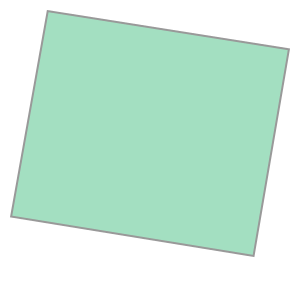

In [120]:
geo = philly_demo_final.iloc[0].geometry
geo

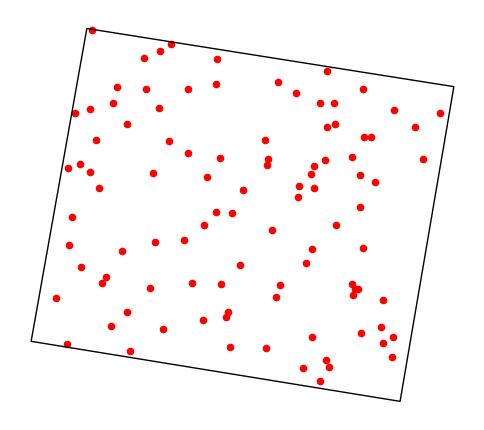

In [121]:
fig, ax = plt.subplots(figsize=(6, 6))
random_points = random_points_in_polygon(100, geo, rng=42)
gpd.GeoSeries(random_points, crs=philly_demo_final.crs).plot(ax=ax, markersize=20, color="red")
gpd.GeoSeries([geo], crs=philly_demo_final.crs).plot(ax=ax, facecolor="none", edgecolor="black")
ax.set_axis_off()
plt.show()

In [122]:
def generate_dot_map(data, people_per_dot, seed=42):
    if not np.isfinite(people_per_dot) or people_per_dot <= 0:
        raise ValueError("people_per_dot must be positive and finite.")
    if data.crs is None or not data.crs.is_projected:
        raise ValueError("Project the polygons before sampling.")
    rng = np.random.default_rng(seed)
    records = []
    for field in race_fields:
        for population, polygon in zip(data[field], data.geometry):
            if not np.isfinite(population) or population < 0:
                raise ValueError(f"Invalid population in {field}.")
            expected_dots = population / people_per_dot
            # Stochastic rounding preserves the expected count; do not always round up.
            count = int(np.floor(expected_dots))
            count += int(rng.random() < expected_dots - count)
            records.extend(
                {"field": field, "geometry": point}
                for point in random_points_in_polygon(count, polygon, rng)
            )
    return gpd.GeoDataFrame(records, columns=["field", "geometry"], geometry="geometry", crs=data.crs)

### Step 3: Generate the dot-map dataset

Each dot represents approximately 50 people. Fractional dot counts are rounded probabilistically, so totals are approximate rather than rounded upward in every block group. The fixed seed makes repeated runs reproducible.

In [123]:
PEOPLE_PER_DOT = 50
dot_map = generate_dot_map(philly_demo_final, people_per_dot=PEOPLE_PER_DOT, seed=42)
if dot_map.empty:
    raise ValueError("No dots were generated. Check population counts and people_per_dot.")

In [124]:
print("number of points = ", len(dot_map))

number of points =  31926


In [125]:
dot_map.tail()

,field,geometry
31921,Other,POINT (492018.941 4431275.427)
31922,Other,POINT (481485.722 4419706.486)
31923,Other,POINT (483106.091 4430224.145)
31924,Other,POINT (498608.73 4431504.97)
31925,Other,POINT (498787.396 4430399.53)


### Step 4: Plot the racial dot map

In [126]:
colors = {
    "Black": "steelblue", "White": "tomato", "Hispanic": "khaki",
    "Asian": "palegreen", "Other": "darkgray",
}

In [127]:
# Convert to 3857
dot_map_3857 = dot_map.to_crs(epsg=3857)

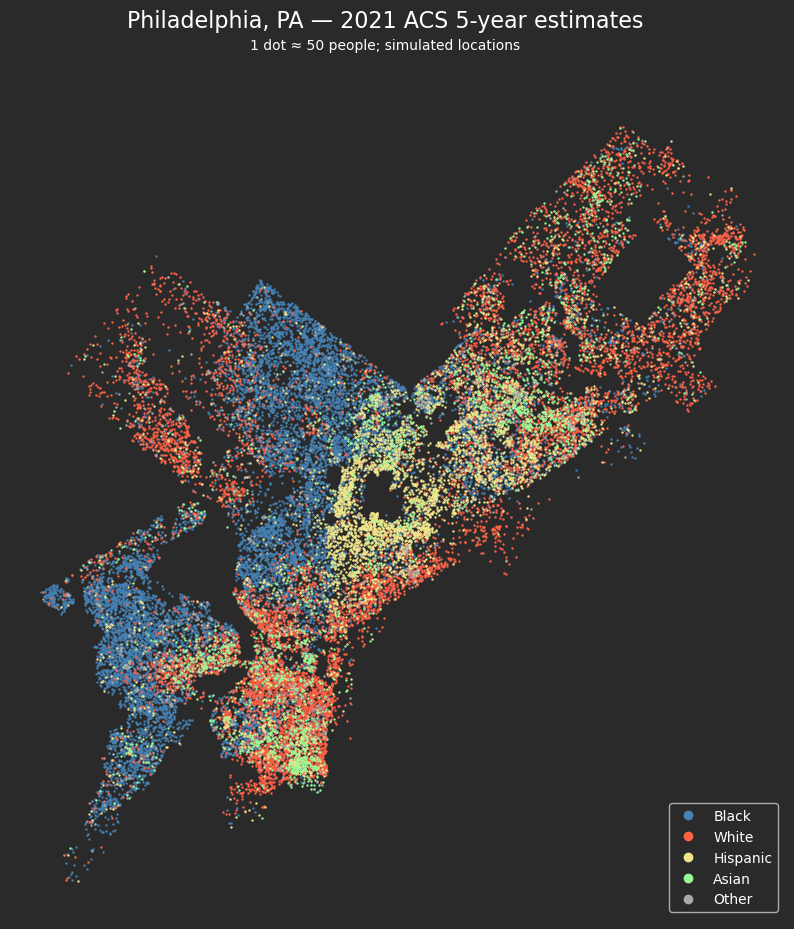

In [129]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 10), facecolor="#2a2a2a")
ax.set_facecolor("#2a2a2a")
for field, color in colors.items():
    subset = dot_map_3857.loc[dot_map_3857["field"].eq(field)]
    if not subset.empty:
        subset.plot(ax=ax, color=color, markersize=0.5)
handles = [Line2D([], [], marker="o", linestyle="", color=color, label=field)
           for field, color in colors.items()]
ax.set_aspect("equal", adjustable="datalim")
legend = ax.legend(handles=handles, loc="lower right", facecolor="#2a2a2a")
for text in legend.get_texts():
    text.set_color("white")
fig.suptitle(f"Philadelphia, PA — {ACS_YEAR} ACS 5-year estimates", fontsize=16, color="white", y=0.96)
fig.text(0.5, 0.92, f"1 dot ≈ {PEOPLE_PER_DOT} people; simulated locations",
         fontsize=10, ha="center", color="white")
fig.subplots_adjust(top=0.88, bottom=0.05)
ax.set_axis_off()
plt.show()

## Wrap-up and next steps

You can now manage records with SQLite, request Census metadata and ACS estimates with `requests`, convert JSON responses into DataFrames, join demographic records to matching Census boundaries, and create a reproducible dot map.

**Discussion:** How does one dot’s population value affect the map’s appearance?